# Exercice 1

## 1

In [4]:
import pandas as pd
import numpy as np
import jupyter as jpy
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [14]:
# Définition des données
X = [[1], [2.1], [3]]
y = [[1], [2], [3]]

# Création et ajustement du modèle
modele = LinearRegression()
modele.fit(X, y)

# Prédiction pour x_pred = [[4]]
x_pred = [[4]]
prediction = modele.predict(x_pred)

prediction

array([[3.96013289]])

## 2

In [23]:
# Affichage des coefficients
print(f"Coefficients: {modele.coef_[0][0]}")

# Affichage de l'ordonnée à l'origine
print(f"Intercept {modele.intercept_[0]}")

# Affichage du score (R²)
print(f"Score: {modele.score(X, y)}")

Coefficients: 0.9966777408637878
Intercept -0.026578073089701615
Score: 0.9966777408637874


# Exercie 2

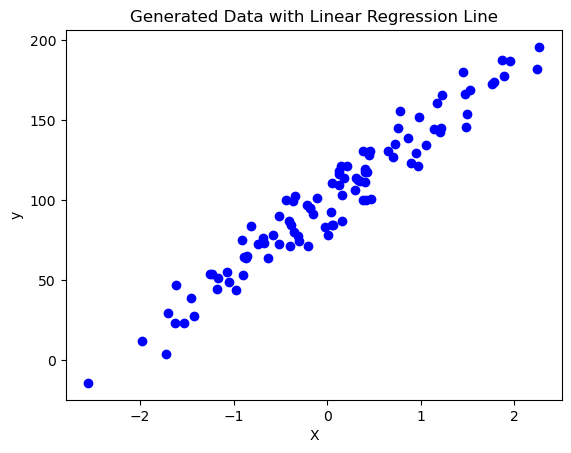

In [26]:
from sklearn.datasets import make_regression


X, y, coef = make_regression(n_samples=100,
                         n_features=1,
                         n_informative=1,
                         noise=10,
                         coef=True,
                         random_state=0,
                         bias=100.0)

plt.scatter(X,y, c='b')

plt.title("Generated Data with Linear Regression Line")
plt.xlabel("X")
plt.ylabel("y")
plt.show()

In [28]:
model = LinearRegression()
model.fit(X, y)
coef = model.coef_
intercept = model.intercept_
print(f'y = {coef[0]} * x + {intercept}')


y = 42.619430291366946 * x + 99.18581817296929


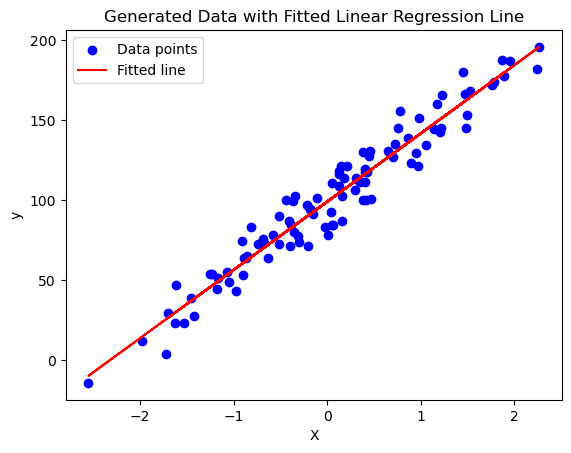

In [30]:
plt.scatter(X, y, color='blue', label='Data points')
plt.plot(X, model.predict(X), color='red', label='Fitted line')
plt.title(f"Generated Data with Fitted Linear Regression Line")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [32]:
print(model.predict(X)[:10])

[ 83.86186727 140.80961751 116.3333897   64.52998689  61.34889539
 118.10301628  57.5347917  117.44107847 108.06237908  85.90762675]


In [35]:
from sklearn.metrics import mean_squared_error
def compute_mse(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return mse
y_pred = model.predict(X)
print(compute_mse(y, y_pred))

114.17148616819485


In [37]:
X, y, coef = make_regression(n_samples=100,
                         n_features=1,
                         n_informative=1,
                         noise=50,
                         coef=True,
                         random_state=0,
                         bias=100.0)
model = LinearRegression()
model.fit(X, y)
coef = model.coef_
intercept = model.intercept_

y_pred = model.predict(X)
print("\nMSE :",compute_mse(y, y_pred))


MSE : 2854.2871542048706


# Exercise 3

In [39]:
from sklearn.model_selection import train_test_split

# Générer les données
X = np.arange(1, 21).reshape(10, -1)
y = np.arange(1, 11)

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Afficher les ensembles divisés
print("X_train:\n", X_train)
print("y_train:\n", y_train)
print("X_test:\n", X_test)
print("y_test:\n", y_test)

X_train:
 [[ 1  2]
 [ 3  4]
 [ 5  6]
 [ 7  8]
 [ 9 10]
 [11 12]
 [13 14]
 [15 16]]
y_train:
 [1 2 3 4 5 6 7 8]
X_test:
 [[17 18]
 [19 20]]
y_test:
 [ 9 10]


# Exercise 4

In [42]:
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True)
X, y = diabetes.data, diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True,random_state=43)
print(y_train.values[:10])
print(y_test.values[:10])

[202.  55. 202.  42. 214. 173. 118.  90. 129. 151.]
[ 71.  72. 235. 277. 109.  61. 109.  78.  66. 192.]


In [44]:
model = LinearRegression()
model.fit(X_train,y_train)
a = model.coef_
b = model.intercept_
feature_names = list(X.columns)
coefs_with_names = list(zip(feature_names, a))
coefs_with_names.append(('intercept', b))

# Print the results
print("Coefficients:")
for name, coef in coefs_with_names:
    print(f"    ('{name}', {coef})")



Coefficients:
    ('age', -60.399848093335535)
    ('sex', -226.08359044269187)
    ('bmi', 529.3849571887343)
    ('bp', 259.9619941214204)
    ('s1', -859.0930093348031)
    ('s2', 504.68697338961937)
    ('s3', 157.4108578803282)
    ('s4', 226.2931343552117)
    ('s5', 840.7840406049221)
    ('s6', 34.712265555717224)
    ('intercept', 152.0532454782767)


In [46]:
y_pred = model.predict(X_test)

# Print the predictions
print("\nPredictions on the test set:")
print(y_pred[:10])



Predictions on the test set:
[111.74267934  98.41608992 168.36714629 255.06351455 168.44138847
 117.60698984 198.8733865  126.2932775  117.72876579 224.82776308]


In [48]:
y_train_pred = model.predict(X_train)
mse_train = compute_mse(y_train, y_train_pred)
print("mse train: ",mse_train)
y_test_pred = model.predict(X_test)
mse_test = compute_mse(y_test, y_test_pred)
print("mse test: ",mse_test)

mse train:  2888.324598377127
mse test:  2858.2915057597875
